# Gauss fit
messing around and learning to fit a gauss curve

Fit parameters: A=274.91+-408.30, mean=10.04+-0.07, sigma=30.24+-23.20, D=-258.89+-408.41


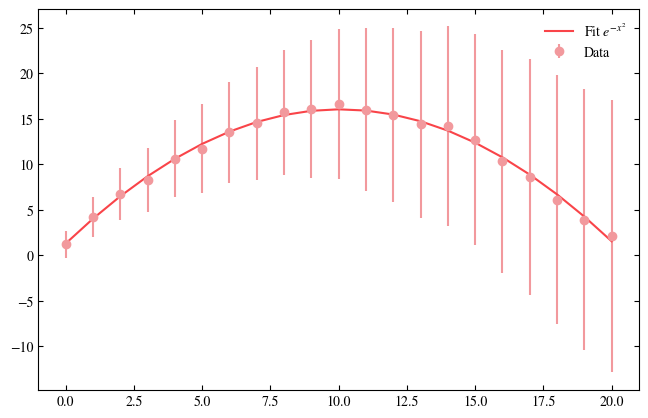

In [30]:
# play around with gaussian
import numpy as np
from matplotlib import pyplot as plt
import scipy

plt.style.use('stylesheet.mplstyle')
np.random.seed(0)

xdata = np.array([-10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
xdata = np.add(xdata, 10.0)
ydata = np.array([1.2, 4.2, 6.7, 8.3, 10.6, 11.7, 13.5, 14.5, 15.7, 16.1, 16.6, 16.0, 15.4, 14.4, 14.2, 12.7, 10.3, 8.6, 6.1, 3.9, 2.1])
#ydata_err = np.abs(np.random.normal(0.0,10.0,len(ydata)))
#ydata_err = np.full(len(ydata), fill_value=1.0)
ydata_err = np.linspace(0.1*15, 15, len(ydata))

# Gaussian function
def gaus(x,a,x0,sigma, d):
    return a*np.exp(-(x-x0)**2/(2*sigma**2)) + d

parameters, pcov = scipy.optimize.curve_fit(gaus, xdata, ydata, p0=[1, 10.0, 1.0, 0.0], sigma=ydata_err)
fit_A, fit_B, fit_C, fit_D = parameters
err_A, err_B, err_C, err_D = np.sqrt(np.diag(pcov)) # diagonal elements are one standart deviation of parameter
fit_y = gaus(xdata, fit_A, fit_B, fit_C, fit_D)
print(f"Fit parameters: A={fit_A:.2f}+-{err_A:.2f}, mean={fit_B:.2f}+-{err_B:.2f}, sigma={fit_C:.2f}+-{err_C:.2f}, D={fit_D:.2f}+-{err_D:.2f}")

plt.errorbar(xdata, ydata, ydata_err, fmt='o', label='Data')
plt.plot(xdata, fit_y, '-', label=r'Fit $e^{-x^2}$')
plt.legend()
plt.show()


In [25]:
sigmas = np.linspace(0,10,11)
for sigma in sigmas:
    #ydata_err = np.abs(np.random.normal(0.0,sigma,len(ydata)))
    #ydata_err = np.full(len(ydata), fill_value=sigma)
    ydata_err = np.linspace(0.1*(sigma+1), 1.5*(sigma+1), len(ydata))
    parameters, pcov = scipy.optimize.curve_fit(gaus, xdata, ydata, p0=[1, 10.0, 1.0, 0.0], sigma=ydata_err)
    fit_A, fit_B, fit_C, fit_D = parameters
    err_A, err_B, err_C, err_D = np.sqrt(np.diag(pcov)) # diagonal elements are one standart deviation of parameter
    fit_y = gaus(xdata, fit_A, fit_B, fit_C, fit_D)
    print(f"For sigma = {sigma}:")
    print(f"Fit parameters: A={fit_A:.2f}+-{err_A:.2f}, mean={fit_B:.2f}+-{err_B:.2f}, sigma={fit_C:.2f}+-{err_C:.2f}, D={fit_D:.2f}+-{err_D:.2f}")

For sigma = 0.0:
Fit parameters: A=1282.17+-8959.20, mean=10.05+-0.08, sigma=66.08+-232.56, D=-1266.20+-8959.33
For sigma = 1.0:
Fit parameters: A=1282.17+-8959.20, mean=10.05+-0.08, sigma=66.08+-232.56, D=-1266.20+-8959.33
For sigma = 2.0:
Fit parameters: A=1297.24+-9165.23, mean=10.05+-0.08, sigma=66.47+-236.51, D=-1281.27+-9165.36
For sigma = 3.0:
Fit parameters: A=1282.17+-8959.20, mean=10.05+-0.08, sigma=66.08+-232.56, D=-1266.20+-8959.33
For sigma = 4.0:
Fit parameters: A=1291.06+-9083.17, mean=10.05+-0.08, sigma=66.32+-234.96, D=-1275.09+-9083.30
For sigma = 5.0:
Fit parameters: A=1297.24+-9165.23, mean=10.05+-0.08, sigma=66.47+-236.51, D=-1281.27+-9165.36
For sigma = 6.0:
Fit parameters: A=1293.95+-9124.18, mean=10.05+-0.08, sigma=66.39+-235.75, D=-1277.98+-9124.31
For sigma = 7.0:
Fit parameters: A=1282.17+-8959.20, mean=10.05+-0.08, sigma=66.08+-232.56, D=-1266.20+-8959.33
For sigma = 8.0:
Fit parameters: A=1296.65+-9163.29, mean=10.05+-0.08, sigma=66.46+-236.51, D=-1280.68+-